### Required Discussion 19:1: Building a Recommender System with SURPRISE

This discussion focuses on exploring additional algorithms with the `Suprise` library to generate recommendations.  Your goal is to identify the optimal algorithm by minimizing the mean squared error using cross validation. You are also going to select a dataset to use from [grouplens](https://grouplens.org/datasets/movielens/) example datasets.  

To begin, head over to [grouplens](https://grouplens.org/datasets/movielens/) and examine the different datasets available.  Choose one so that it is easy to create the data as expected in `Surprise` with user, item, and rating information.  Then, compare the performance of at least the `KNNBasic`, `SVD`, `NMF`, `SlopeOne`, and `CoClustering` algorithms to build your recommendations.  For more information on the algorithms see the documentation for the algorithm package [here](https://surprise.readthedocs.io/en/stable/prediction_algorithms_package.html).

Share the results of your investigation and include the results of your cross validation and a basic description of your dataset with your peers.


In [1]:
# Install once in a separate notebook cell if necessary:
# %pip install "numpy<2" pandas matplotlib scikit-surprise
# Restart the Jupyter kernel after installation if the import fails.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from surprise import Dataset, Reader, SVD, NMF, KNNBasic, SlopeOne, CoClustering
from surprise.model_selection import cross_validate, KFold
from IPython.display import display

In [2]:
# Load the official MovieLens 100K file stored in the GitHub project data folder.
from pathlib import Path
import pandas as pd
from surprise import Dataset, Reader

candidates = [Path('data/ml-100k/u.data'), Path('../data/ml-100k/u.data')]
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Place the official MovieLens 100K file at data/ml-100k/u.data and run Jupyter from the project root or notebooks folder.')

ratings_df = pd.read_csv(data_path, sep='\t', header=None,
                         names=['user_id', 'movie_id', 'rating', 'timestamp'])
reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(ratings_df[['user_id', 'movie_id', 'rating']], reader)
print('Dataset file:', data_path.resolve())
print(f'Ratings: {len(ratings_df):,}; users: {ratings_df.user_id.nunique():,}; movies: {ratings_df.movie_id.nunique():,}')
print('Rating range:', ratings_df.rating.min(), 'to', ratings_df.rating.max())
display(ratings_df.head())
assert len(ratings_df) == 100_000, 'Expected original MovieLens 100K.'


Dataset file: /Users/aravat/Documents/Python/Working/Module_19/Assignment_19_1_SURPRISE_Recommendation_System/data/ml-100k/u.data
Ratings: 100,000; users: 943; movies: 1,682
Rating range: 1 to 5


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [3]:
# Same seeded 5-fold partition for every algorithm.
# Cross-validation reports RMSE and MAE; per-fold MSE = RMSE ** 2.
SEED = 42
algorithms = {
    'KNNBasic': KNNBasic(verbose=False),
    'SVD': SVD(random_state=SEED),
    'NMF': NMF(random_state=SEED),
    'SlopeOne': SlopeOne(),
    'CoClustering': CoClustering(random_state=SEED),
}
results = []
fold_details = []
for name, algorithm in algorithms.items():
    print(f'Evaluating {name} ...')
    cv = KFold(n_splits=5, random_state=SEED, shuffle=True)
    scores = cross_validate(algorithm, data, measures=['RMSE', 'MAE'], cv=cv, n_jobs=1, verbose=False)
    mse_folds = np.square(scores['test_rmse'])
    results.append({'Algorithm': name, 'Mean MSE': mse_folds.mean(),
                    'Std MSE': mse_folds.std(ddof=1),
                    'Mean RMSE': scores['test_rmse'].mean(),
                    'Mean MAE': scores['test_mae'].mean(),
                    'Mean Fit Time (s)': np.mean(scores['fit_time'])})
    for fold, (mse, rmse, mae) in enumerate(zip(mse_folds, scores['test_rmse'], scores['test_mae']), 1):
        fold_details.append({'Algorithm': name, 'Fold': fold, 'MSE': mse, 'RMSE': rmse, 'MAE': mae})
results_df = pd.DataFrame(results).sort_values('Mean MSE').reset_index(drop=True)
folds_df = pd.DataFrame(fold_details)
print('Cross-validation summary (lower is better):')
display(results_df.round(4))
print('Per-fold scores:')
display(folds_df.round(4))

Evaluating KNNBasic ...
Evaluating SVD ...
Evaluating NMF ...
Evaluating SlopeOne ...
Evaluating CoClustering ...
Cross-validation summary (lower is better):


,Algorithm,Mean MSE,Std MSE,Mean RMSE,Mean MAE,Mean Fit Time (s)
0,SVD,0.8742,0.0075,0.9350,0.7372,0.3447
1,SlopeOne,0.8917,0.0058,0.9443,0.7422,0.1783
2,NMF,0.9260,0.0054,0.9623,0.7565,0.4761
3,CoClustering,0.9325,0.0080,0.9657,0.7559,0.3256
4,KNNBasic,0.9583,0.0091,0.9789,0.7735,0.0610


Per-fold scores:


,Algorithm,Fold,MSE,RMSE,MAE
0,KNNBasic,1,0.9501,0.9748,0.7689
1,KNNBasic,2,0.9489,0.9741,0.7703
2,KNNBasic,3,0.9710,0.9854,0.7804
3,KNNBasic,4,0.9609,0.9803,0.7751
4,KNNBasic,5,0.9607,0.9802,0.7727
5,SVD,1,0.8735,0.9346,0.7376
6,SVD,2,0.8681,0.9317,0.7345
7,SVD,3,0.8866,0.9416,0.7417
8,SVD,4,0.8682,0.9318,0.7347
9,SVD,5,0.8745,0.9352,0.7375


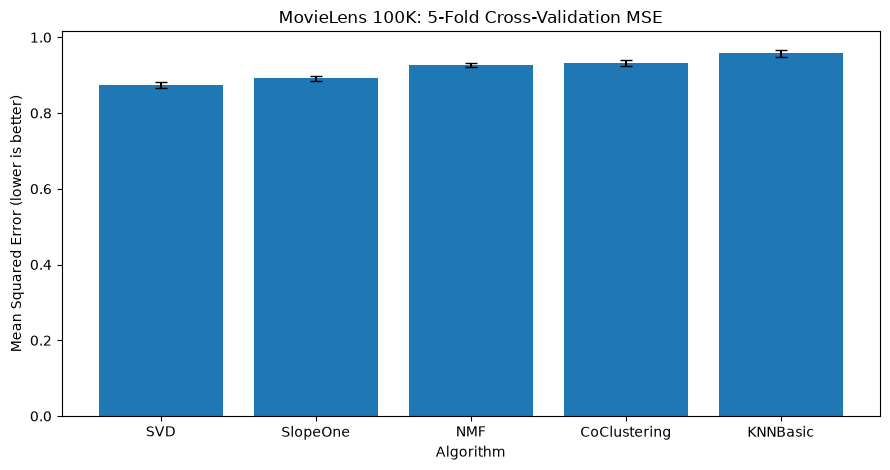

Best algorithm by mean MSE: SVD (0.8742)


In [4]:
# Plot model comparison and save machine-readable results.
project_root = Path.cwd()
if not (project_root / 'README.md').exists():
    project_root = project_root.parent
assert (project_root / 'README.md').exists(), 'Run from project root or notebooks/ folder.'
figures_dir = project_root / 'outputs' / 'figures'
reports_dir = project_root / 'outputs' / 'reports'
figures_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)
results_df.to_csv(reports_dir / 'cross_validation_summary.csv', index=False)
folds_df.to_csv(reports_dir / 'cross_validation_folds.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(results_df['Algorithm'], results_df['Mean MSE'], yerr=results_df['Std MSE'], capsize=4)
ax.set(title='MovieLens 100K: 5-Fold Cross-Validation MSE', ylabel='Mean Squared Error (lower is better)', xlabel='Algorithm')
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(figures_dir / 'model_comparison.png', dpi=160)
plt.show()
print(f"Best algorithm by mean MSE: {results_df.iloc[0]['Algorithm']} ({results_df.iloc[0]['Mean MSE']:.4f})")

In [5]:
# Create an expanded discussion post using the ACTUAL results (not placeholders).
best = results_df.loc[results_df['Mean MSE'].idxmin()]
score_lines = '\n'.join(
    f"- {r['Algorithm']}: MSE {r['Mean MSE']:.4f}; RMSE {r['Mean RMSE']:.4f}; MAE {r['Mean MAE']:.4f}"
    for _, r in results_df.iterrows()
)
github_url = ('https://github.com/trilokreddyarava/Trilok_Berkley_AI_ML_PC/'
              'tree/main/Module_19/Assignment_19_1_SURPRISE_Recommendation_System')
post = f"""Building a Recommendation System with the SURPRISE Library — Discussion 19.1

Dataset and objective
I selected the original MovieLens 100K dataset from GroupLens to investigate how well collaborative filtering algorithms can predict movie ratings. The dataset contains 100,000 ratings from 943 users for 1,682 movies, with a rating scale from 1 to 5. Each observation identifies a user, a movie, and the user's rating. Accurate rating predictions can support personalized content discovery, although rating accuracy alone does not establish the quality of a ranked recommendation list.

Approach
I compared five SURPRISE algorithms: KNNBasic, SVD, NMF, SlopeOne, and CoClustering. I used the same shuffled five-fold cross-validation partition (random seed 42) for each algorithm. The primary selection metric was mean squared error (MSE), computed by squaring each fold's RMSE and then averaging those fold-level MSE values. I also examined RMSE and mean absolute error (MAE); lower values indicate smaller prediction errors.

Five-fold cross-validation results (lower is better)
{score_lines}

Findings and interpretation
The best-performing algorithm among the five tested was {best['Algorithm']}, with an average MSE of {best['Mean MSE']:.4f}, average RMSE of {best['Mean RMSE']:.4f}, and average MAE of {best['Mean MAE']:.4f}. This model achieved the lowest average squared rating prediction error in this comparison. Results are based on this dataset, split, and the tested algorithm settings; they do not establish that the model will always outperform alternatives.

Business relevance and next steps
This experiment illustrates how recommendation approaches can be compared using a reproducible evaluation process. A next step would be to tune hyperparameters, evaluate top-N recommendation metrics such as precision@K and recall@K, and assess recommendation coverage and novelty before considering production use.

GitHub project: {github_url}
"""
(reports_dir / 'discussion_post.txt').write_text(post, encoding='utf-8')
print(f'Best algorithm: {best["Algorithm"]}')
print(f'Lowest average MSE: {best["Mean MSE"]:.4f}')
print(f'Expanded post word count: {len(post.split())} (instructor limit: 200 words)')
print(post)


Best algorithm: SVD
Lowest average MSE: 0.8742
Expanded post word count: 307 (instructor limit: 200 words)
Building a Recommendation System with the SURPRISE Library — Discussion 19.1

Dataset and objective
I selected the original MovieLens 100K dataset from GroupLens to investigate how well collaborative filtering algorithms can predict movie ratings. The dataset contains 100,000 ratings from 943 users for 1,682 movies, with a rating scale from 1 to 5. Each observation identifies a user, a movie, and the user's rating. Accurate rating predictions can support personalized content discovery, although rating accuracy alone does not establish the quality of a ranked recommendation list.

Approach
I compared five SURPRISE algorithms: KNNBasic, SVD, NMF, SlopeOne, and CoClustering. I used the same shuffled five-fold cross-validation partition (random seed 42) for each algorithm. The primary selection metric was mean squared error (MSE), computed by squaring each fold's RMSE and then averagi

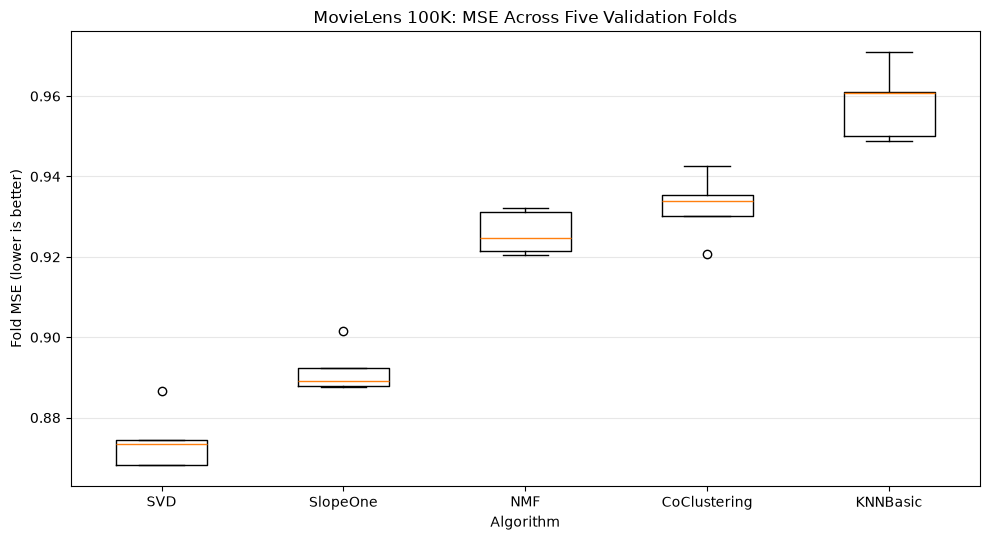


Generated files:
OK /Users/aravat/Documents/Python/Working/Module_19/Assignment_19_1_SURPRISE_Recommendation_System/outputs/figures/model_comparison.png
OK /Users/aravat/Documents/Python/Working/Module_19/Assignment_19_1_SURPRISE_Recommendation_System/outputs/figures/cross_validation_mse.png
OK /Users/aravat/Documents/Python/Working/Module_19/Assignment_19_1_SURPRISE_Recommendation_System/outputs/reports/cross_validation_summary.csv
OK /Users/aravat/Documents/Python/Working/Module_19/Assignment_19_1_SURPRISE_Recommendation_System/outputs/reports/cross_validation_folds.csv
OK /Users/aravat/Documents/Python/Working/Module_19/Assignment_19_1_SURPRISE_Recommendation_System/outputs/reports/discussion_post.txt

Best algorithm: SVD
Best mean MSE: 0.8742


In [6]:
# Additional report and visualization: MSE variation across the five CV folds.
# Run this after the model evaluation and previous export cells.
fig, ax = plt.subplots(figsize=(10, 5.5))
order = results_df['Algorithm'].tolist()
fold_values = [folds_df.loc[folds_df['Algorithm'] == alg, 'MSE'].to_numpy() for alg in order]
ax.boxplot(fold_values, tick_labels=order)
ax.set(title='MovieLens 100K: MSE Across Five Validation Folds',
       xlabel='Algorithm', ylabel='Fold MSE (lower is better)')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / 'cross_validation_mse.png', dpi=200, bbox_inches='tight')
plt.show()

# Confirm the full set of requested deliverables.
expected = [
    figures_dir / 'model_comparison.png',
    figures_dir / 'cross_validation_mse.png',
    reports_dir / 'cross_validation_summary.csv',
    reports_dir / 'cross_validation_folds.csv',
    reports_dir / 'discussion_post.txt',
]
print('\nGenerated files:')
for path in expected:
    print(('OK' if path.exists() else 'MISSING'), path)
print('\nBest algorithm:', results_df.iloc[0]['Algorithm'])
print('Best mean MSE:', f"{results_df.iloc[0]['Mean MSE']:.4f}")


In [7]:
best = results_df.loc[results_df["Mean MSE"].idxmin()]

print("Best Algorithm:", best["Algorithm"])
print("Lowest Average MSE:", round(best["Mean MSE"], 4))

Best Algorithm: SVD
Lowest Average MSE: 0.8742


In [8]:
print(results_df.head())
print(folds_df.head())

      Algorithm  Mean MSE   Std MSE  Mean RMSE  Mean MAE  Mean Fit Time (s)
0           SVD  0.874203  0.007523   0.934981  0.737216           0.344725
1      SlopeOne  0.891749  0.005847   0.944320  0.742248           0.178300
2           NMF  0.925985  0.005401   0.962278  0.756537           0.476063
3  CoClustering  0.932527  0.007963   0.965667  0.755871           0.325640
4      KNNBasic  0.958323  0.009058   0.978931  0.773483           0.061022
  Algorithm  Fold       MSE      RMSE       MAE
0  KNNBasic     1  0.950142  0.974752  0.768882
1  KNNBasic     2  0.948884  0.974107  0.770319
2  KNNBasic     3  0.970962  0.985374  0.780386
3  KNNBasic     4  0.960930  0.980270  0.775134
4  KNNBasic     5  0.960695  0.980151  0.772692


Project directory: /Users/aravat/Documents/Python/Working/Module_19/Assignment_19_1_SURPRISE_Recommendation_System
Generated: cross_validation_summary.csv
Generated: cross_validation_folds.csv

Best Algorithm: SVD
Lowest Average MSE: 0.8742


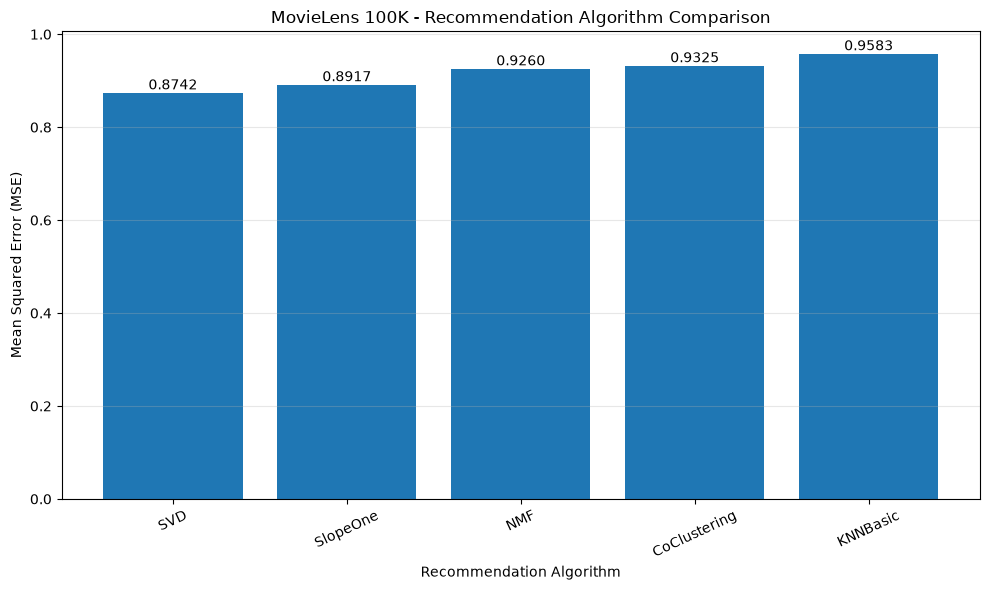

Generated: model_comparison.png


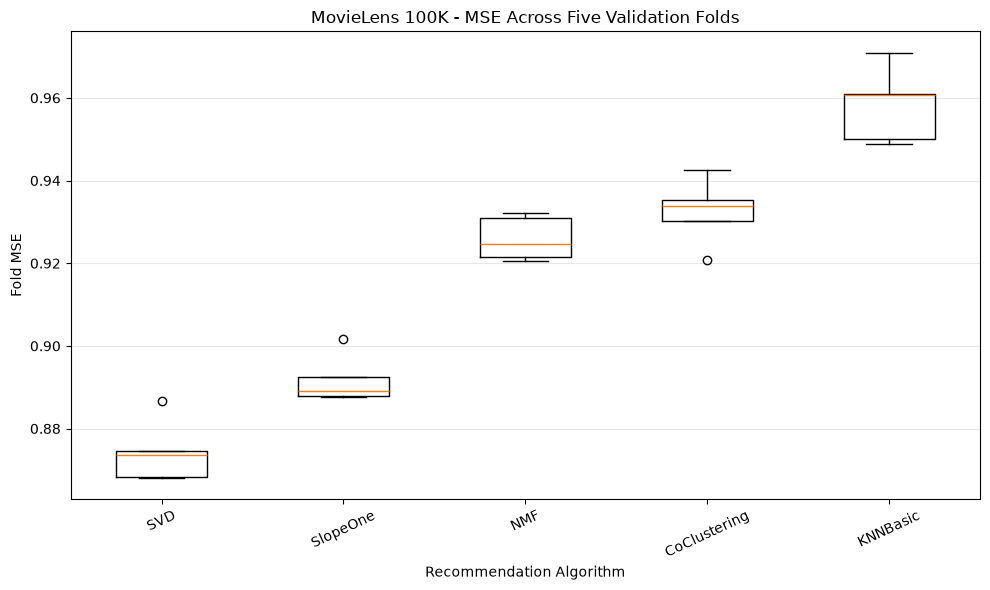

Generated: cross_validation_mse.png
Generated: discussion_post.txt

FINAL PROJECT OUTPUT VERIFICATION
OK: outputs/figures/model_comparison.png
OK: outputs/figures/cross_validation_mse.png
OK: outputs/reports/cross_validation_summary.csv
OK: outputs/reports/cross_validation_folds.csv
OK: outputs/reports/discussion_post.txt

Best Algorithm: SVD
Lowest Average MSE: 0.8742

All reports and visualizations generated successfully!


In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# 1. SET UP PROJECT DIRECTORIES
# =====================================================

cwd = Path.cwd()

if (cwd / "notebooks").is_dir():
    project_root = cwd
elif cwd.name == "notebooks":
    project_root = cwd.parent
else:
    raise FileNotFoundError(
        "Please run Jupyter from the project root or notebooks folder."
    )

figures_dir = project_root / "outputs" / "figures"
reports_dir = project_root / "outputs" / "reports"

figures_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

print("Project directory:", project_root.resolve())

# =====================================================
# 2. SAVE CROSS-VALIDATION SUMMARY
# =====================================================

results_df.to_csv(
    reports_dir / "cross_validation_summary.csv",
    index=False
)

print("Generated: cross_validation_summary.csv")

# =====================================================
# 3. SAVE CROSS-VALIDATION FOLD RESULTS
# =====================================================

folds_df.to_csv(
    reports_dir / "cross_validation_folds.csv",
    index=False
)

print("Generated: cross_validation_folds.csv")

# =====================================================
# 4. IDENTIFY THE BEST ALGORITHM
# =====================================================

best = results_df.loc[
    results_df["Mean MSE"].idxmin()
]

best_algorithm = best["Algorithm"]
best_mse = best["Mean MSE"]

print("\nBest Algorithm:", best_algorithm)
print("Lowest Average MSE:", round(best_mse, 4))

# =====================================================
# 5. VISUALIZATION 1: MODEL COMPARISON
# =====================================================

comparison = results_df.sort_values("Mean MSE")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    comparison["Algorithm"],
    comparison["Mean MSE"]
)

ax.set_title(
    "MovieLens 100K - Recommendation Algorithm Comparison"
)

ax.set_xlabel("Recommendation Algorithm")
ax.set_ylabel("Mean Squared Error (MSE)")

ax.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    figures_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Generated: model_comparison.png")

# =====================================================
# 6. VISUALIZATION 2: CROSS-VALIDATION MSE
# =====================================================

order = results_df["Algorithm"].tolist()

fold_values = [
    folds_df.loc[
        folds_df["Algorithm"] == alg,
        "MSE"
    ].to_numpy()
    for alg in order
]

fig, ax = plt.subplots(figsize=(10, 6))

# Matplotlib version compatibility
import inspect

boxplot_params = inspect.signature(ax.boxplot).parameters

label_argument = (
    "tick_labels"
    if "tick_labels" in boxplot_params
    else "labels"
)

ax.boxplot(
    fold_values,
    **{label_argument: order}
)

ax.set_title(
    "MovieLens 100K - MSE Across Five Validation Folds"
)

ax.set_xlabel("Recommendation Algorithm")
ax.set_ylabel("Fold MSE")

ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    figures_dir / "cross_validation_mse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Generated: cross_validation_mse.png")

# =====================================================
# 7. GENERATE EXPANDED DISCUSSION POST
# =====================================================

mse_results = "\n".join(
    f"{row['Algorithm']}: {row['Mean MSE']:.4f}"
    for _, row in results_df.iterrows()
)

discussion_post = f"""
MODULE 19 - REQUIRED DISCUSSION 19.1
BUILDING A RECOMMENDATION SYSTEM USING SURPRISE

1. PROJECT OBJECTIVE

The objective of this assignment was to develop and
evaluate collaborative filtering recommendation algorithms
using Python's SURPRISE library.

I explored different machine learning approaches for
predicting movie ratings and identifying the most
accurate recommendation model.

2. DATASET DESCRIPTION

I used the MovieLens 100K dataset from GroupLens.

Dataset characteristics:
- 100,000 movie ratings
- 943 unique users
- 1,682 movies
- Rating scale: 1 to 5 stars

The dataset captures interactions between users and
movies and is suitable for collaborative filtering.

3. ALGORITHMS EVALUATED

I implemented five recommendation algorithms:

- KNNBasic
- SVD (Singular Value Decomposition)
- NMF (Non-negative Matrix Factorization)
- SlopeOne
- CoClustering

4. CROSS-VALIDATION METHODOLOGY

I used five-fold cross-validation to compare the
algorithms consistently.

The evaluation metrics included:

- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)

MSE was the primary metric used to select the
best-performing algorithm.

5. CROSS-VALIDATION RESULTS

Mean MSE for each algorithm:

{mse_results}

BEST-PERFORMING ALGORITHM: {best_algorithm}
LOWEST AVERAGE MSE: {best_mse:.4f}

6. KEY FINDINGS

The best-performing algorithm was {best_algorithm},
achieving the lowest average MSE of {best_mse:.4f}.

This indicates that {best_algorithm} produced the
smallest average squared rating prediction error
among the five algorithms evaluated.

The results demonstrate the importance of evaluating
multiple collaborative filtering approaches using
cross-validation.

7. BUSINESS APPLICATIONS

Recommendation systems help organizations:

- Personalize products and content.
- Improve content discovery.
- Support customer engagement.
- Identify relevant recommendations.
- Improve the overall customer experience.

8. CONCLUSION

This assignment provided practical experience in
developing and comparing recommendation algorithms
using the SURPRISE library.

Based on five-fold cross-validation, {best_algorithm}
achieved the lowest average MSE of {best_mse:.4f}.

Future improvements could include hyperparameter
tuning, larger datasets, and top-N recommendation
evaluation using precision and recall.
"""

discussion_post = discussion_post.strip()

(reports_dir / "discussion_post.txt").write_text(
    discussion_post,
    encoding="utf-8"
)

print("Generated: discussion_post.txt")

# =====================================================
# 8. VERIFY ALL FIVE FILES
# =====================================================

expected_files = [
    figures_dir / "model_comparison.png",
    figures_dir / "cross_validation_mse.png",
    reports_dir / "cross_validation_summary.csv",
    reports_dir / "cross_validation_folds.csv",
    reports_dir / "discussion_post.txt",
]

print("\n" + "=" * 60)
print("FINAL PROJECT OUTPUT VERIFICATION")
print("=" * 60)

for file in expected_files:
    status = "OK" if file.exists() else "MISSING"
    print(f"{status}: {file.relative_to(project_root)}")

print("\nBest Algorithm:", best_algorithm)
print("Lowest Average MSE:", f"{best_mse:.4f}")

print("\nAll reports and visualizations generated successfully!")